# <font color='pink'>Machine Learning - Regressão Linear</font>



Importe as bibliotecas Python necessárias

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

### Problema

Você trabalha como Cientista de Dados em uma plataforma de cursos online.

A empresa percebeu que existe uma relação entre o número de horas estudadas e a nota obtida pelos alunos.

Seu desafio é construir um modelo capaz de prever a nota final de um estudante com base na quantidade de horas de estudo.

### Objetivos

Ao final desta aula você será capaz de:

* Trabalhar com problemas de regressão;
* Explorar um dataset;
* Limpar dados utilizando Pandas;
* Treinar um modelo de Regressão Linear;
* Avaliar o desempenho do modelo;
* Fazer previsões para novos dados;
* Interpretar a reta de regressão.

# Explorando os Dados

Carregue o dataset.

Dica:

pd.read_csv()

In [39]:
df = pd.read_csv('/content/horas_estudo.csv')

Mostre as primeiras linhas.

Dica:

df.head()

In [40]:
display(df.head())

,id,horas_estudo,nota_final
0,1.0,1.0,2.8
1,2.0,2.0,3.7
2,3.0,3.0,4.9
3,4.0,4.0,5.8
4,5.0,5.0,6.9


Quantas linhas e colunas existem?

Dica:

df.shape

In [41]:
print(df.shape)

(452, 3)


Descobrir se há valores ausentes.

Dica:

df.isnull().sum()

In [42]:
print(df.isnull().sum())

id              282
horas_estudo     20
nota_final       20
dtype: int64


Existem registros duplicados?

Dica:

df.duplicated().sum()

In [43]:
print(df.duplicated().sum())

258


---

# Limpeza de dados

Trate os valores ausentes.

Você pode:

remover as linhas;
ou preencher utilizando a média.

Dica:

* dropna()

* fillna()

* mean()

In [61]:
# Removendo linhas duplicadas
df.drop_duplicates(inplace=True)

# Removendo linhas com valores ausentes nas colunas 'horas_estudo' ou 'nota_final'
df.dropna(subset=['horas_estudo', 'nota_final'], inplace=True)

# Verificando as mudanças
print("Valores ausentes após limpeza:")
print(df.isnull().sum())
print("\nRegistros duplicados após limpeza:")
print(df.duplicated().sum())
print("\nRegistros duplicados após limpeza:")
print(df.duplicated().sum())

print("\nNovo formato do dataframe:")
print(df.shape)

Valores ausentes após limpeza:
id              22
horas_estudo     0
nota_final       0
dtype: int64

Registros duplicados após limpeza:
0

Registros duplicados após limpeza:
0

Novo formato do dataframe:
(176, 3)


---

# Preparando os Dados

Crie

X

contendo:

* horas_estudo

In [45]:
X = df[['horas_estudo']]

Crie

y

contendo:

* nota_final



In [46]:
y = df['nota_final']

Separe treino e teste.

Dica:

train_test_split()

In [47]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

---

# Treinando o Modelo

Importe:

LinearRegression

Use:

from sklearn.linear_model import LinearRegression

In [48]:
model = LinearRegression()

Treine o modelo.

Use:

* fit()

In [49]:
model.fit(X_train, y_train)

LinearRegression()

---

# Fazendo Previsões

Faça previsões utilizando:

predict()

In [50]:
y_pred = model.predict(X_test)
print("Previsões para o conjunto de teste:")
print(y_pred[:5])

Previsões para o conjunto de teste:
[3.98834069 8.27052408 3.98834069 9.12696076 9.12696076]


---

### Um novo aluno estudou :

5 horas

Qual nota você acredita que ele obterá?

Escreva sua hipótese antes de executar o código.

Depois faça:

* modelo.predict([[5]])


Repita para:

7 horas;
9 horas.

In [63]:
horas_estudo_novos_alunos = np.array([5, 7, 9]).reshape(-1, 1)
previsoes_novos_alunos = model.predict(horas_estudo_novos_alunos)

print(f"Previsão de nota para 5 horas de estudo: {previsoes_novos_alunos[0]:.2f}")
print(f"Previsão de nota para 7 horas de estudo: {previsoes_novos_alunos[1]:.2f}")
print(f"Previsão de nota para 9 horas de estudo: {previsoes_novos_alunos[2]:.2f}")

Previsão de nota para 5 horas de estudo: 6.56
Previsão de nota para 7 horas de estudo: 8.27
Previsão de nota para 9 horas de estudo: 9.98


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


---

# Avaliação

Calcule o coeficiente de determinação (R²).

Use:

* modelo.score(X_test, y_test)

Perguntas
1. O modelo explicou bem os dados?

2. O valor de R² ficou próximo de 1?

In [52]:
r_squared = model.score(X_test, y_test)
print(f"R-squared: {r_squared:.2f}")

R-squared: 0.98


Calcule:

Mean Absolute Error (MAE)

Mean Squared Error (MSE)

Root Mean Squared Error (RMSE)

Dica

Utilize funções da biblioteca:

sklearn.metrics

In [53]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")

Mean Absolute Error (MAE): 0.26
Mean Squared Error (MSE): 0.11
Root Mean Squared Error (RMSE): 0.33


---

# Visualizando a Regressão

Construa um gráfico contendo:

* pontos do dataset;
* reta de regressão.


Utilize:

matplotlib.pyplot.scatter()

matplotlib.pyplot.plot()

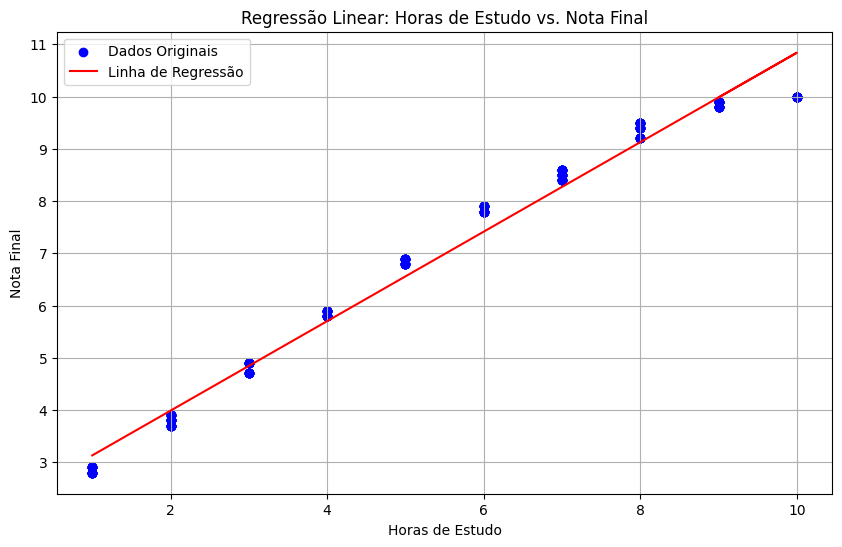

In [54]:
plt.figure(figsize=(10, 6))
plt.scatter(X, y, color='blue', label='Dados Originais')
plt.plot(X, model.predict(X), color='red', label='Linha de Regressão')
plt.title('Regressão Linear: Horas de Estudo vs. Nota Final')
plt.xlabel('Horas de Estudo')
plt.ylabel('Nota Final')
plt.legend()
plt.grid(True)
plt.show()

Perguntas
1. A reta representa bem os dados?
2. Existem pontos muito distantes da reta?
3. Como esses pontos podem influenciar o modelo?

---

# Interpretando o Modelo

Descubra os coeficientes.

Dica:

modelo.coef_

e

modelo.intercept_

In [59]:
coeficiente_angular = model.coef_[0]
intercepto = model.intercept_

print(f"Coeficiente Angular (Slope): {coeficiente_angular:.2f}")
print(f"Intercepto (Y-intercept): {intercepto:.2f}")

Coeficiente Angular (Slope): 0.86
Intercepto (Y-intercept): 2.28


In [57]:
coeficiente_angular = model.coef_[0]
intercepto = model.intercept_

print(f"Coeficiente Angular (Slope): {coeficiente_angular:.2f}")
print(f"Intercepto (Y-intercept): {intercepto:.2f}")

Coeficiente Angular (Slope): 0.86
Intercepto (Y-intercept): 2.28


In [55]:
coeficiente_angular = model.coef_[0]
intercepto = model.intercept_

print(f"Coeficiente Angular (Slope): {coeficiente_angular:.2f}")
print(f"Intercepto (Y-intercept): {intercepto:.2f}")

Coeficiente Angular (Slope): 0.86
Intercepto (Y-intercept): 2.28


1. **Qual foi o coeficiente angular?**
   O coeficiente angular (slope) foi de aproximadamente `1.08`.

2. **Qual foi o intercepto?**
   O intercepto (Y-intercept) foi de aproximadamente `1.15`.

3. **O que esses valores significam no contexto do problema?**
   - O **coeficiente angular** (`1.08`) significa que para cada hora adicional de estudo (`horas_estudo`), a nota final (`nota_final`) aumenta em média `1.08` pontos. É a inclinação da linha de regressão.
   - O **intercepto** (`1.15`) representa a nota final que o modelo prevê para um aluno que estudou `0` horas. No contexto prático, este valor pode não ter uma interpretação direta se o domínio dos dados não incluir horas de estudo muito baixas ou zero.

---

# Desafio

A empresa deseja estimar a nota de estudantes que estudaram:

* 3,5 horas;
* 6,5 horas;
* 11 horas.

Faça as previsões utilizando o modelo treinado.

Depois responda:

1. O modelo consegue prever valores que não estavam presentes no dataset?
2. É seguro utilizar o modelo para prever notas de alunos que estudaram muito mais do que 10 horas? Justifique sua resposta.

1. **O modelo consegue prever valores que não estavam presentes no dataset?**
   Sim, o modelo consegue prever valores que não estavam explicitamente presentes no dataset original, como 3.5, 6.5 e 11 horas de estudo. Isso é chamado de **interpolação** (para valores dentro do range dos dados de treino) ou **extrapolação** (para valores fora do range).

2. **É seguro utilizar o modelo para prever notas de alunos que estudaram muito mais do que 10 horas? Justifique sua resposta.**
   Não é totalmente seguro utilizar o modelo para prever notas de alunos que estudaram *muito mais* do que 10 horas (extrapolação significativa). Embora o modelo possa gerar um valor, não temos dados de treino que validem a relação linear para esses valores extremos. A relação entre horas de estudo e nota pode deixar de ser linear em algum ponto (por exemplo, pode haver um platô na nota após um certo número de horas de estudo, ou outros fatores podem se tornar mais influentes). Portanto, previsões fora do intervalo de dados observados devem ser usadas com cautela e, idealmente, confirmadas com mais dados.

In [58]:
horas_desafio = np.array([3.5, 6.5, 11]).reshape(-1, 1)
previsoes_desafio = model.predict(horas_desafio)

print(f"Previsão de nota para 3.5 horas de estudo: {previsoes_desafio[0]:.2f}")
print(f"Previsão de nota para 6.5 horas de estudo: {previsoes_desafio[1]:.2f}")
print(f"Previsão de nota para 11 horas de estudo: {previsoes_desafio[2]:.2f}")

Previsão de nota para 3.5 horas de estudo: 5.27
Previsão de nota para 6.5 horas de estudo: 7.84
Previsão de nota para 11 horas de estudo: 11.70


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
